# 04 · Secondary analysis – ASCA at protein level

**Why this analysis is added.** Notebook 03 works on shares of the proteome, which are constrained to sum to 1. ASCA works on log-transformed individual proteins and asks a complementary, multivariate question: *after removing the dataset effect, how much of the protein-level variation follows growth rate, and which proteins and categories move most?*

**Model.** `X = X_batch + X_growth + X_batch×growth + E`, fitted in that order (sequential sums of squares):

| term | meaning |
|---|---|
| `X_batch` | one mean level per batch (platform / laboratory offset) |
| `X_growth` | one growth-rate slope per protein, **shared by all batches** |
| `X_batch×growth` | how far each batch's own slope departs from the shared slope |
| `E` | residual |

The interaction tests the key assumption of the project: that the studies agree on how the proteome changes with growth rate.'


**Preprocessing, in this order (all parameters in `config.yml`)**

1. in-scope samples only;
2. keep proteins quantified in every in-scope sample of **every** dataset (logical AND). The matrix is then complete and **no value is imputed**. The earlier OR rule kept proteins that one platform never measured and then filled whole columns with half-minimum values;
3. log10;
4. average replicates to conditions;
5. column mean-centring – last, on the final set of rows.

The detection filter never looks at growth rate, and ASCA is descriptive, so there is no label leakage. The price is a smaller protein set, reported below.

In [1]:
import sys
from pathlib import Path

# repository root = first parent folder that contains config.yml (no machine-specific paths)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from proteome_alloc import config, ingest, annotation, scope, allocation, asca, predict, plots, combined, proteomap
from proteome_alloc.ingest import GROWTH

cfg = config.load_config()
pd.set_option("display.max_columns", 40, "display.width", 220, "display.max_colwidth", 60)
print("Repository root :", cfg.root)
print("Config file     :", cfg.config_file.name, "| master seed:", cfg["seed"])

Repository root : C:\Users\arlin\OneDrive\Documentos\proteome_allocation\proteome_allocation
Config file     : config.yml | master seed: 20261011


In [2]:
X, obs, var = scope.load_scoped(cfg)
annotation_table = annotation.load_annotation(cfg)
labels = annotation.category_labels(cfg)
in_scope = obs.index[obs["In_Scope"]]

L, report = asca.prepare_protein_matrix(X.loc[in_scope], obs.loc[in_scope], cfg)
for key, value in report.items():
    print(f"{key:48s} {value}")

Lc, info = allocation.aggregate_conditions(L, obs.loc[in_scope], cfg)
print("\nMatrix analysed (conditions x proteins):", Lc.shape)

proteins_in_merged_matrix                        4449
proteins_kept                                    944
threshold_per_dataset                            1.0
values_imputed_half_minimum                      0
share_imputed                                    0.0
log_base                                         10
mass_fraction_covered_by_kept_proteins_min       0.747816315450001

Matrix analysed (conditions x proteins): (27, 944)


## 1 · PCA before and after removing the dataset effect

PCA of the combined protein matrix (log10, column-centred, no scaling) is the first look at what dominates the data.

* **Before**: if conditions group by study rather than by growth rate, the platform/laboratory effect is larger than the biology - the reason the dataset term is in every model.
* **After**: each batch's offset, estimated jointly with growth rate, is subtracted from every protein. If growth rate then orders the conditions along a principal component, the four studies describe one common proteome response.

The dendrograms show the same comparison as a clustering of conditions (Ward linkage on the centred data). Both figures are exploratory: no p-value is taken from them.

PC1+PC2 before: 52.5% | after: 71.1% of variance
Pearson r between PC1 and growth rate, before: +0.94
Pearson r between PC1 and growth rate, after: +0.95


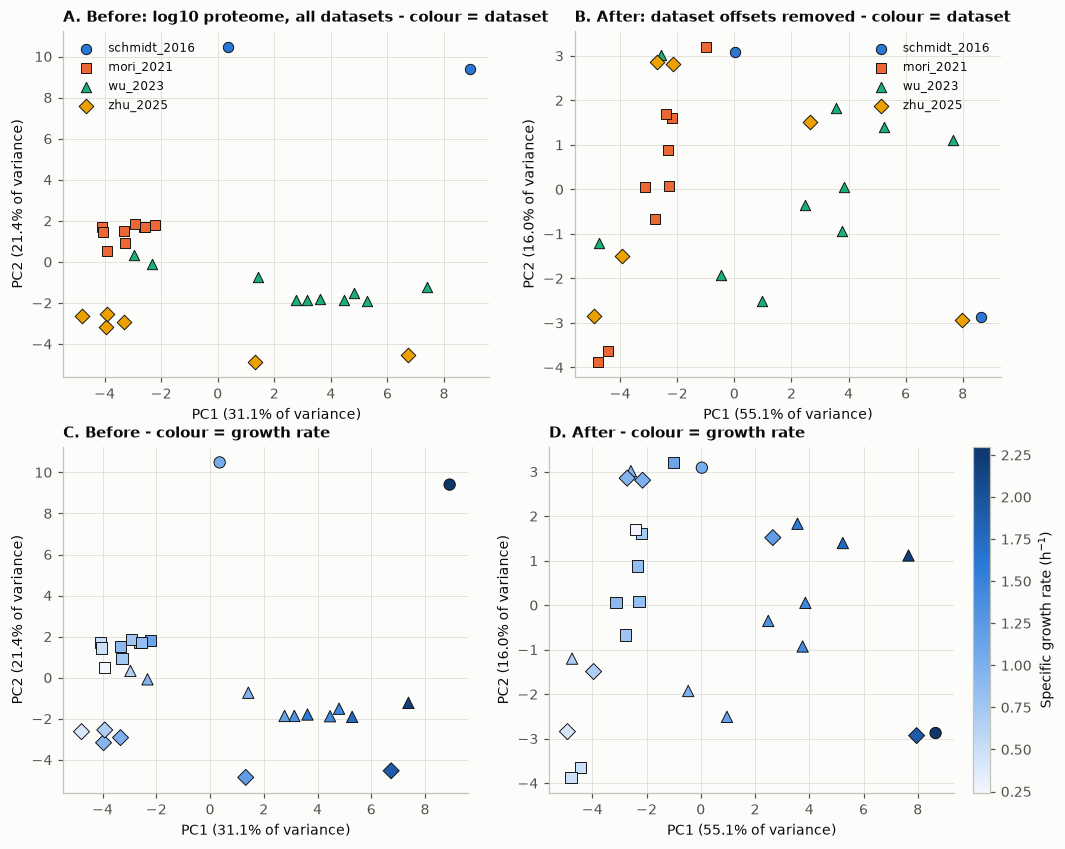

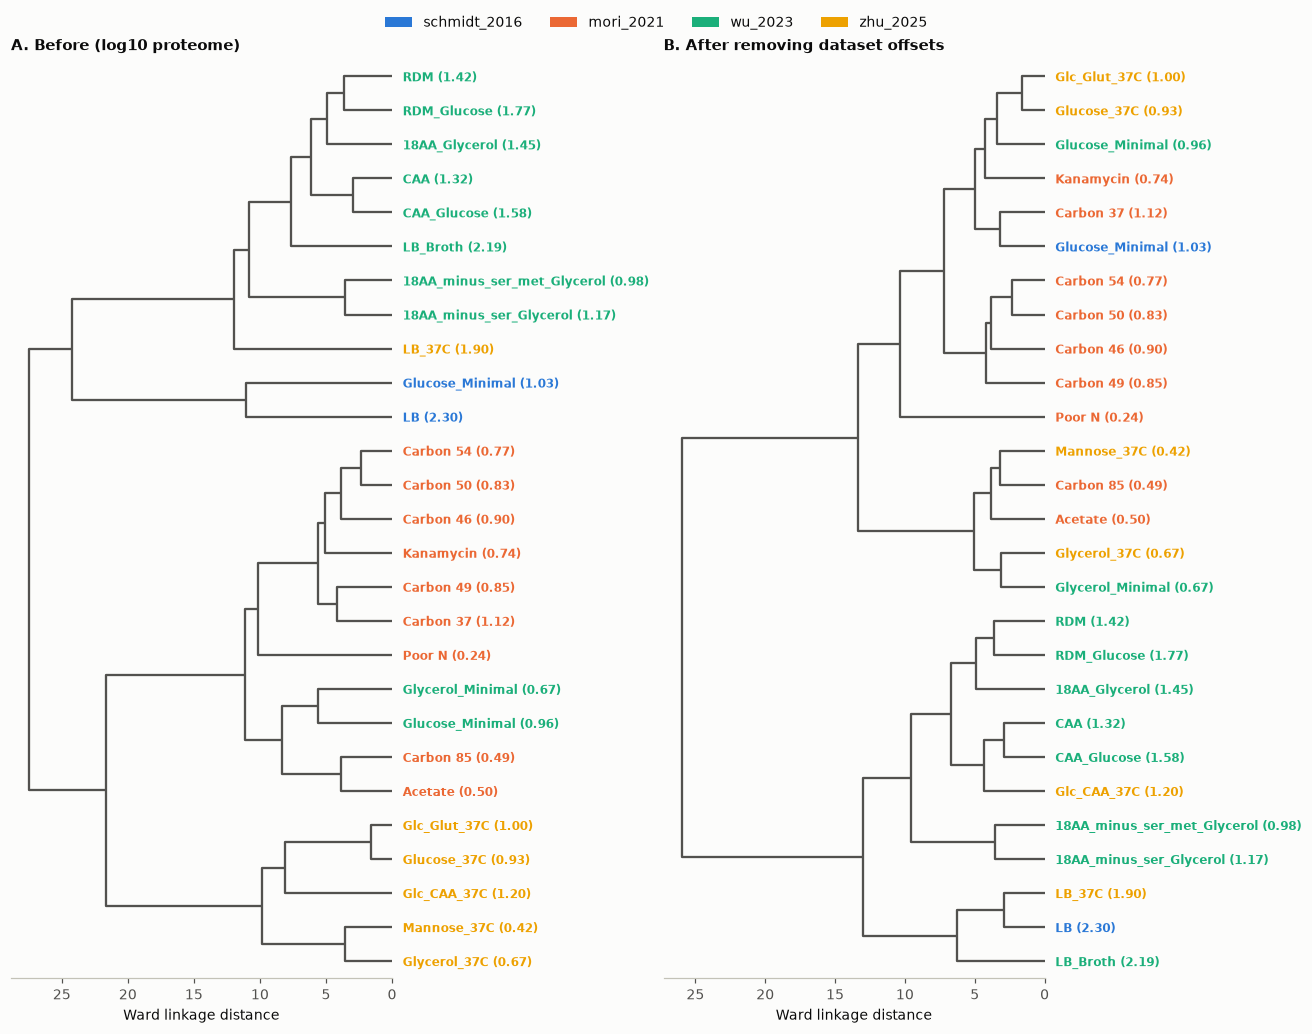

In [3]:
batch_key = cfg["allocation"]["batch_key"]
L_after = combined.remove_batch_effect(Lc, info, batch_key)
growth = info[GROWTH]
scores_before, ratio_before = combined.pca_scores(Lc, orient=growth)        # PC signs oriented: + = faster growth
scores_after, ratio_after = combined.pca_scores(L_after, orient=growth)
print(f"PC1+PC2 before: {ratio_before[:2].sum():.1%} | after: {ratio_after[:2].sum():.1%} of variance")
for name, scores in (("before", scores_before), ("after", scores_after)):
    r = np.corrcoef(scores["PC1"], info.loc[scores.index, GROWTH])[0, 1]
    print(f"Pearson r between PC1 and growth rate, {name}: {r:+.2f}")

fig = plots.plot_pca_before_after(scores_before, scores_after, ratio_before, ratio_after, info,
                                  cfg.figures / "04_pca_before_after.png")
plt.show()
cond_labels = combined.condition_labels(info)
fig = plots.plot_condition_dendrograms(Lc, L_after, info, cond_labels, cfg.figures / "04_condition_dendrograms.png")
plt.show()

`mass_fraction_covered_by_kept_proteins_min` tells how much of the proteome mass the retained proteins represent in the least-covered sample: the analysis describes the consistently quantified, mostly abundant part of the proteome.

## 2 · ASCA decomposition and permutation test

The test statistic is the sum of squares of the growth effect. Growth rates are permuted within each dataset, so the dataset structure is identical in every permutation.

,SS,SS_fraction,df,p_permutation
Dataset,829.2077,0.5595,3,NaN
Growth rate | dataset,253.9020,0.1713,1,0.001
Dataset x growth rate,101.4781,0.0685,3,0.013
Residual,297.4669,0.2007,19,NaN
Total (centred),1482.0547,1.0000,26,NaN


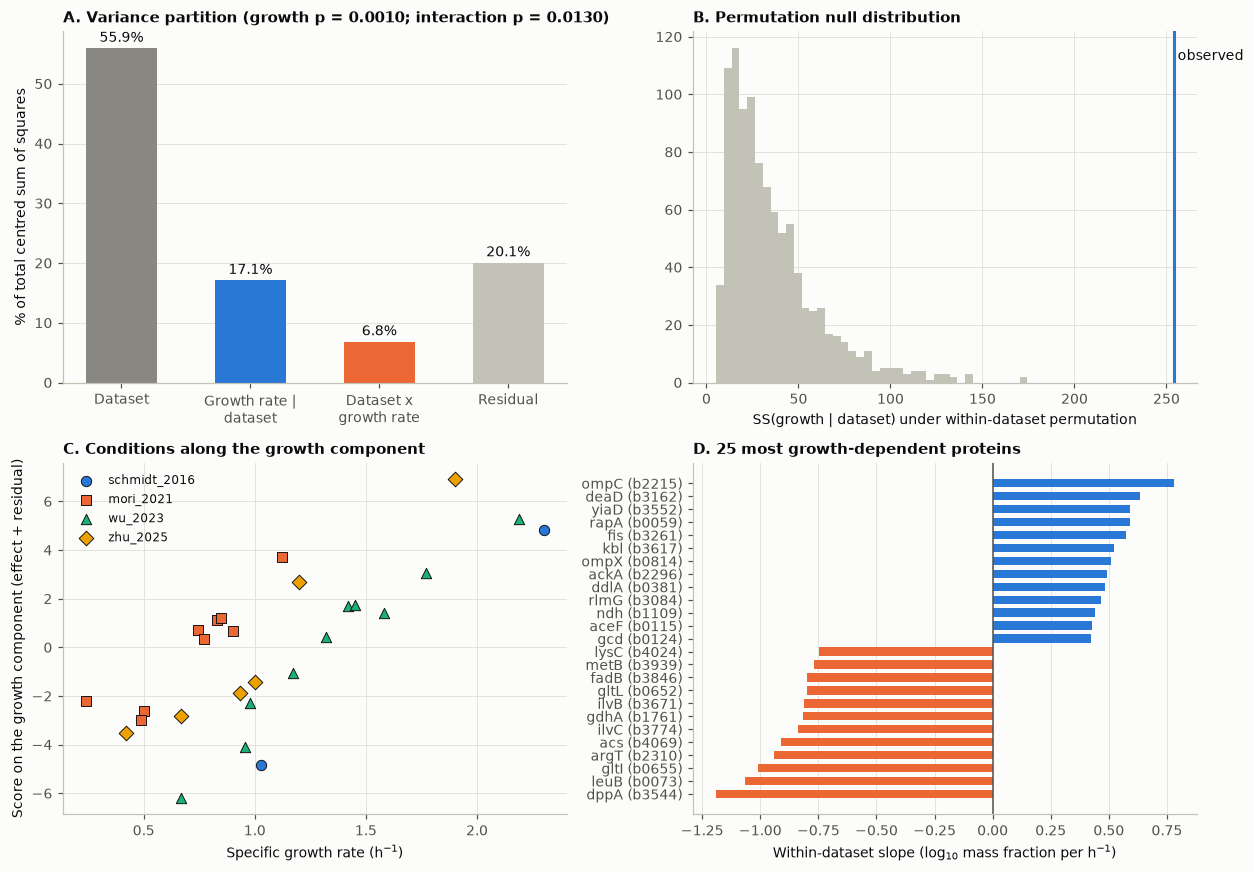

In [4]:
result = asca.run_asca(Lc, info, cfg, gene_names=var["Gene_Name"])
display(result.variance_table.round(4))
fig = plots.plot_asca(result, cfg.figures / "04_asca_overview.png", top_n=cfg["asca"]["top_n"],
                      batch_key=cfg["allocation"]["batch_key"])
plt.show()

In [5]:
print(f"Shared growth slope        : SS share {result.variance_table.loc['Growth rate | dataset', 'SS_fraction']:.1%}, p = {result.p_growth:.4f}")
print(f"Batch x growth interaction : SS share {result.variance_table.loc['Dataset x growth rate', 'SS_fraction']:.1%}, "
      f"df = {result.params['interaction_df']}, pseudo-F = {result.params['interaction_pseudo_F']:.2f}, p = {result.p_interaction:.4f}")
print("\nProteins whose growth response differs most between batches:")
display(result.protein_table.sort_values("interaction_share_of_protein_SS", ascending=False)
        [["gene", "slope_log_per_h-1", "growth_share_of_protein_SS", "interaction_share_of_protein_SS"]].head(15).round(3))

Shared growth slope        : SS share 17.1%, p = 0.0010
Batch x growth interaction : SS share 6.8%, df = 3, pseudo-F = 2.16, p = 0.0130

Proteins whose growth response differs most between batches:


,gene,slope_log_per_h-1,growth_share_of_protein_SS,interaction_share_of_protein_SS
b_number,,,,
b0812,dps,-0.022,0.001,0.472
b3831,udp,0.132,0.043,0.424
b3605,lldD,0.248,0.110,0.389
b2521,sseA,0.028,0.004,0.362
b3706,mnmE,0.094,0.090,0.333
b0032,carA,-0.143,0.069,0.329
b0733,cydA,0.039,0.006,0.325
b0033,carB,-0.163,0.063,0.315
b1273,yciN,0.159,0.191,0.314


In [6]:
weights = annotation.category_weights(Lc.columns, annotation_table, cfg)
cog_table = asca.cog_summary(result.protein_table, weights, cfg)
display(cog_table.assign(description=labels.reindex(cog_table.index)).round(4))

,n_proteins,median_slope,median_slope_other,rank_biserial,p_mannwhitney,q_BH,description
COG_Category,,,,,,,
J,152,0.2003,-0.0059,0.7036,0.0000,0.0000,"Translation, ribosomal structure and biogenesis"
L,42,0.1161,0.0222,0.3144,0.0006,0.0023,"Replication, recombination and repair"
Q,7,0.1125,0.0277,0.1517,0.4973,0.5850,"Secondary metabolites biosynthesis, transport and catabo..."
U,13,0.1008,0.0265,0.2129,0.1871,0.4157,"Intracellular trafficking, secretion, and vesicular tran..."
I,34,0.0714,0.0257,0.0872,0.3876,0.5169,Lipid transport and metabolism
M,94,0.0502,0.0259,0.0956,0.1278,0.3196,Cell wall/membrane/envelope biogenesis
D,26,0.0423,0.0265,0.0929,0.4188,0.5235,"Cell cycle control, cell division, chromosome partitioning"
O,71,0.0263,0.0292,-0.0682,0.3386,0.5017,"Posttranslational modification, protein turnover, chaper..."
K,61,0.0212,0.0278,0.0196,0.7980,0.7980,Transcription


In [7]:
outputs = [cfg.tables / "04_asca_variance_partition.tsv", cfg.tables / "04_asca_protein_slopes.tsv",
           cfg.tables / "04_asca_cog_summary.tsv", cfg.tables / "04_asca_condition_scores.tsv",
           cfg.tables / "04_pca_scores_before_after.tsv"]
scores_before.add_suffix("_before").join(scores_after.add_suffix("_after")).to_csv(outputs[4], sep="\t")
result.variance_table.to_csv(outputs[0], sep="\t"); result.protein_table.to_csv(outputs[1], sep="\t")
cog_table.assign(description=labels.reindex(cog_table.index)).to_csv(outputs[2], sep="\t"); result.scores.to_csv(outputs[3], sep="\t")

config.log_run(cfg, "04_asca_protein_level", params={"asca": cfg["asca"]}, outputs=outputs,
               notes={**report, **result.params, "p_growth": result.p_growth,
                      "SS_fraction": result.variance_table["SS_fraction"].to_dict()})
print("Tables written to", cfg.tables.relative_to(cfg.root))

Tables written to results\tables
